# 01 — Harris Corner Detector (thuật toán cổ điển)

Notebook này giải thích và kiểm tra thuật toán Harris một tỉ lệ. Phần định nghĩa hàm nằm riêng trong `src/cv_bt2/corner/harris_classic.py`; notebook chỉ gọi hàm, trực quan hóa và đo kết quả.

## Mục tiêu học tập

1. Hiểu gradient ảnh và ma trận cấu trúc (Structure Tensor).
2. Hiểu công thức đáp ứng Harris, vai trò của `sigma_d`, `sigma_i`, `k`.
3. Quan sát NMS và ngưỡng tương đối.
4. Kiểm tra phát hiện các giao điểm bàn cờ, phép quay và ảnh hưởng tham số.

**Quy ước:** tọa độ của điểm là `(row, col)`; ảnh đầu vào được chuyển về ảnh xám `float`. Các ảnh tổng hợp bên dưới có cường độ trong `[0,1]`.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import matplotlib.pyplot as plt
from cv_bt2.corner import *
from cv_bt2.data.synthetic import *
from cv_bt2.visualization import plot_corners, plot_labels

OUT = ROOT / "outputs" / "figures"
OUT.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)


Project root: /mnt/data/Computer_Vision_BT2


## 1. Tạo ảnh bàn cờ tổng hợp

Bàn cờ có 6 × 6 ô. Các giao điểm bên trong là các góc mục tiêu. Tạo ảnh tổng hợp giúp kiểm tra độ chính xác mà không phụ thuộc ảnh tải từ Internet.

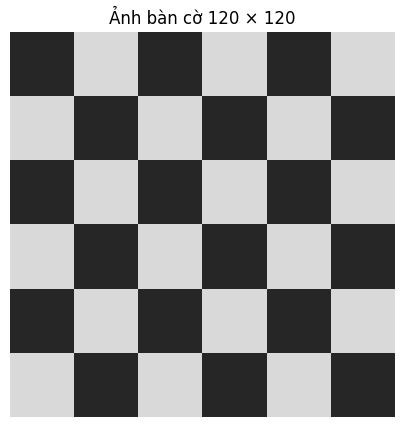

Kích thước: (120, 120) | khoảng cường độ: (np.float64(0.15), np.float64(0.85))


In [2]:
img = checkerboard_image((120, 120), squares=6)
plt.figure(figsize=(5,5)); plt.imshow(img, cmap="gray", vmin=0, vmax=1)
plt.title("Ảnh bàn cờ 120 × 120"); plt.axis("off"); plt.show()
print("Kích thước:", img.shape, "| khoảng cường độ:", (img.min(), img.max()))

## 2. Các bước trung gian của Harris

- Gaussian blur với `sigma_d` giảm nhiễu trước khi tính gradient.
- `Ix`, `Iy` mô tả mức thay đổi cường độ theo hai trục.
- Tích phân các tích gradient tạo `Mxx`, `Mxy`, `Myy`.
- Đáp ứng: `R = det(M) - k * trace(M)^2`.

Hai trị riêng của ma trận cấu trúc cho biết cường độ thay đổi theo hai hướng: cả hai nhỏ → vùng phẳng; một lớn một nhỏ → cạnh; cả hai lớn → góc.

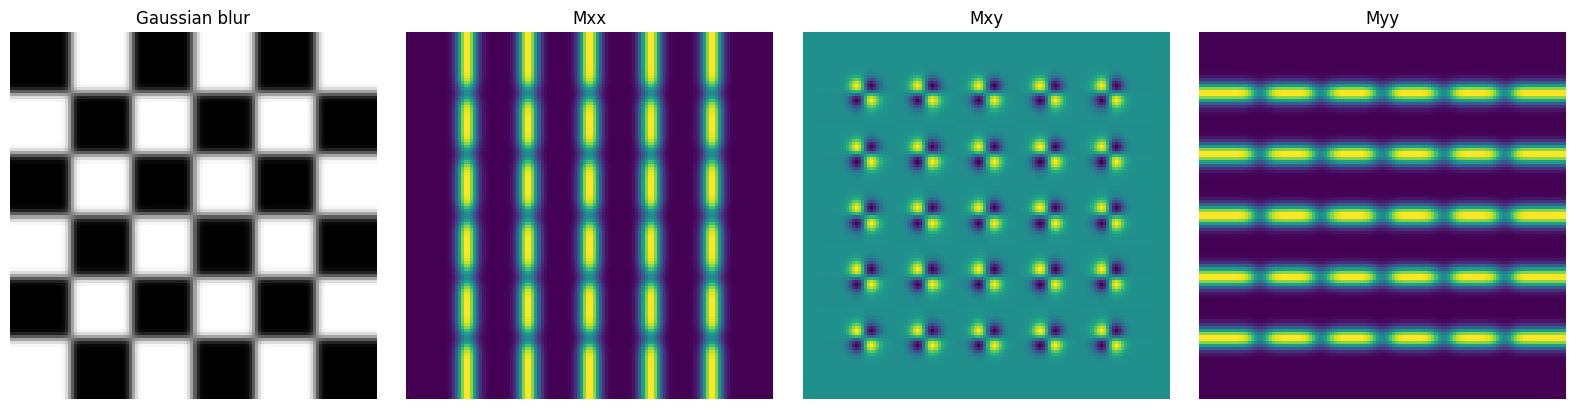

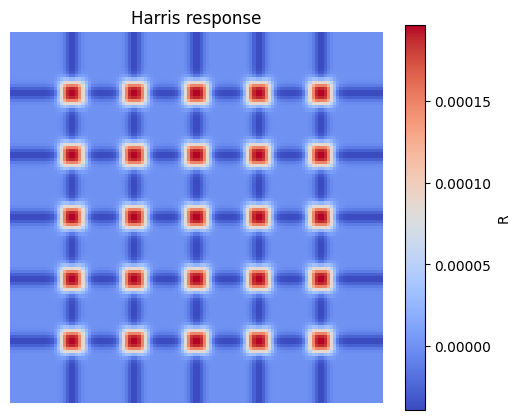

R min/max: -3.923962622043611e-05 0.00019647746433446858


In [3]:
sigma_d, sigma_i, k = 1.4, 2.0, 0.04
blurred = gaussian_blur(img, sigma_d)
Mxx, Mxy, Myy = structure_tensor(img, sigma_i, sigma_d)
R = harris_response(img, sigma_i, sigma_d, k)
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, data, title in zip(ax, [blurred, Mxx, Mxy, Myy],
                         ["Gaussian blur", "Mxx", "Mxy", "Myy"]):
    a.imshow(data, cmap="gray" if title == "Gaussian blur" else "viridis")
    a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()
plt.figure(figsize=(6,5)); plt.imshow(R, cmap="coolwarm"); plt.colorbar(label="R")
plt.title("Harris response"); plt.axis("off"); plt.show()
print("R min/max:", float(R.min()), float(R.max()))

## 3. NMS và phát hiện góc hoàn chỉnh

NMS giữ cực đại cục bộ. Khi một cực đại tạo thành plateau nhiều pixel bằng nhau, hàm cài đặt chọn một đại diện tất định để tránh lặp nhiều điểm quanh cùng một góc. Sau đó áp dụng ngưỡng tương đối theo `max(R)`.

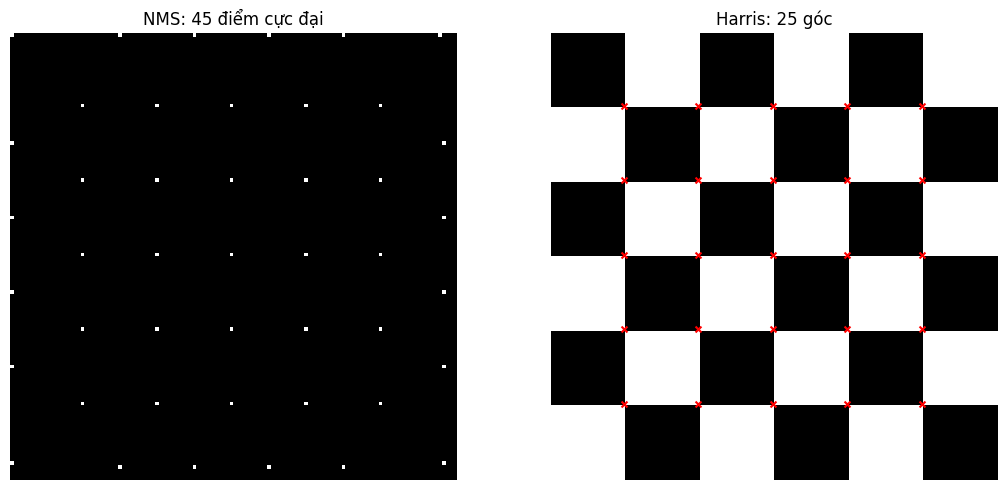

10 điểm đầu [row, col, response]:
 [[1.90000000e+01 1.90000000e+01 1.96477464e-04]
 [1.90000000e+01 3.90000000e+01 1.96477464e-04]
 [1.90000000e+01 5.90000000e+01 1.96477464e-04]
 [1.90000000e+01 7.90000000e+01 1.96477464e-04]
 [1.90000000e+01 9.90000000e+01 1.96477464e-04]
 [3.90000000e+01 1.90000000e+01 1.96477464e-04]
 [3.90000000e+01 3.90000000e+01 1.96477464e-04]
 [3.90000000e+01 5.90000000e+01 1.96477464e-04]
 [3.90000000e+01 7.90000000e+01 1.96477464e-04]
 [3.90000000e+01 9.90000000e+01 1.96477464e-04]]


In [4]:
local_maxima = nms_2d(R, window=3)
points = harris_classic(img, sigma_i=sigma_i, sigma_d=sigma_d, k=k, thresh_rel=0.01)
fig, ax = plt.subplots(1, 2, figsize=(11,5))
ax[0].imshow(local_maxima, cmap="gray"); ax[0].set_title(f"NMS: {local_maxima.sum()} điểm cực đại"); ax[0].axis("off")
plot_corners(img, points, ax=ax[1], title=f"Harris: {len(points)} góc")
plt.tight_layout(); plt.show()
print("10 điểm đầu [row, col, response]:\n", points[:10])

### Kiểm tra giao điểm bàn cờ

Với ảnh được tạo bằng cách chia đều 6 ô theo mỗi chiều, giao điểm bên trong nằm tại ranh giới pixel `(19.5, 39.5, 59.5, 79.5, 99.5)` theo hệ tọa độ pixel-center. Do đó, sai số theo mỗi trục không quá 1 pixel được xem là đạt.

In [5]:
expected = np.array([(r, c) for r in [19.5,39.5,59.5,79.5,99.5]
                              for c in [19.5,39.5,59.5,79.5,99.5]])
if len(points):
    distance_matrix = np.sqrt(np.sum((expected[:, None, :] - points[None, :, :2]) ** 2, axis=2))
    nearest_indices = np.argmin(distance_matrix, axis=1)
    dist = distance_matrix[np.arange(len(expected)), nearest_indices]
    axis_error = np.abs(expected - points[nearest_indices, :2])
    print(f"Số giao điểm mục tiêu: {len(expected)}")
    print(f"Số giao điểm có điểm phát hiện trong sai số 1 px/trục: {(axis_error.max(axis=1) <= 1).sum()}/{len(expected)}")
    print(f"Sai số Euclid trung bình tới điểm gần nhất: {dist.mean():.3f} px")
else:
    print("Không tìm thấy điểm góc.")

Số giao điểm mục tiêu: 25
Số giao điểm có điểm phát hiện trong sai số 1 px/trục: 25/25
Sai số Euclid trung bình tới điểm gần nhất: 0.707 px


## 4. Kiểm tra bất biến phép quay 30°

Harris được thiết kế bất biến với phép quay ở mức đáp ứng lý thuyết. Ta quay ảnh quanh tâm, biến đổi tọa độ các điểm ảnh gốc sang ảnh quay rồi tính repeatability với `eps=3 px`.

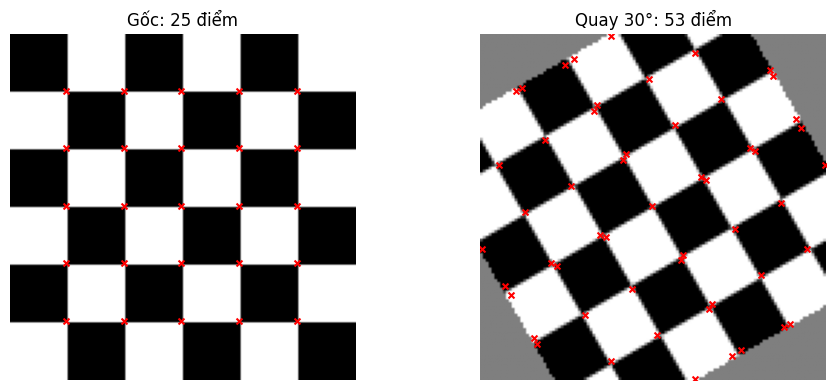

Repeatability sau quay 30°: 1.0000 (100.00%)


In [6]:
angle = 30.0
rotated = rotate_image(img, angle, cval=0.5)
points_rot = harris_classic(rotated, sigma_i=sigma_i, sigma_d=sigma_d, k=k, thresh_rel=0.01)
h, w = img.shape; cy, cx = (h-1)/2, (w-1)/2
theta = np.deg2rad(angle)
def rotate_point(row, col):
    dx, dy = col-cx, row-cy
    # Quy ước phù hợp với scipy.ndimage.rotate trên hệ tọa độ ảnh.
    new_col = np.cos(theta)*dx + np.sin(theta)*dy + cx
    new_row = -np.sin(theta)*dx + np.cos(theta)*dy + cy
    return new_row, new_col
rep_rotation = repeatability(points, points_rot, rotate_point, rotated.shape, eps=3.0)
fig, ax = plt.subplots(1,2,figsize=(10,4))
plot_corners(img, points, ax=ax[0], title=f"Gốc: {len(points)} điểm")
plot_corners(rotated, points_rot, ax=ax[1], title=f"Quay 30°: {len(points_rot)} điểm")
plt.tight_layout(); plt.show()
print(f"Repeatability sau quay 30°: {rep_rotation:.4f} ({rep_rotation:.2%})")

## 5. Quét tham số `thresh_rel`

`thresh_rel` là ngưỡng tương đối so với đáp ứng Harris lớn nhất. Khi tăng ngưỡng, chỉ các góc có response mạnh hơn mới được giữ.

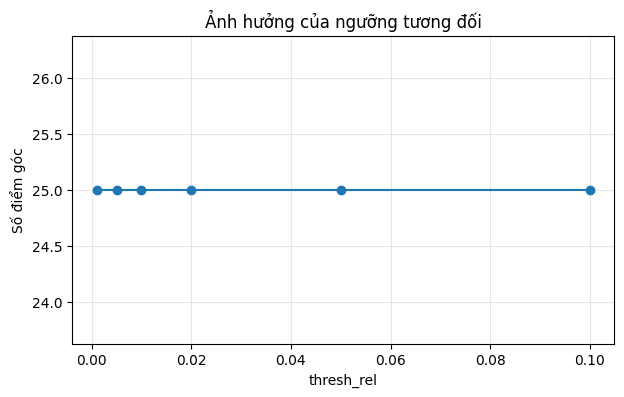

threshold=0.001 -> 25 điểm
threshold=0.005 -> 25 điểm
threshold=0.010 -> 25 điểm
threshold=0.020 -> 25 điểm
threshold=0.050 -> 25 điểm
threshold=0.100 -> 25 điểm


In [7]:
thresholds = [0.001, 0.005, 0.01, 0.02, 0.05, 0.10]
counts = [len(harris_classic(img, sigma_i=2, sigma_d=1.4, thresh_rel=t)) for t in thresholds]
plt.figure(figsize=(7,4)); plt.plot(thresholds, counts, marker="o")
plt.xlabel("thresh_rel"); plt.ylabel("Số điểm góc")
plt.title("Ảnh hưởng của ngưỡng tương đối"); plt.grid(True, alpha=.3); plt.show()
for t, n in zip(thresholds, counts): print(f"threshold={t:.3f} -> {n} điểm")

## 6. Kiểm chứng với OpenCV (tùy chọn)

Theo đề, có thể đối chiếu với `cv2.cornerHarris` trong phần kiểm chứng. OpenCV không được dùng để thay thế hàm tự cài đặt; cell này chỉ so sánh kết quả. Nếu chưa cài OpenCV, cell sẽ bỏ qua.

OpenCV cornerHarris candidates: 225
Harris tự cài đặt: 25


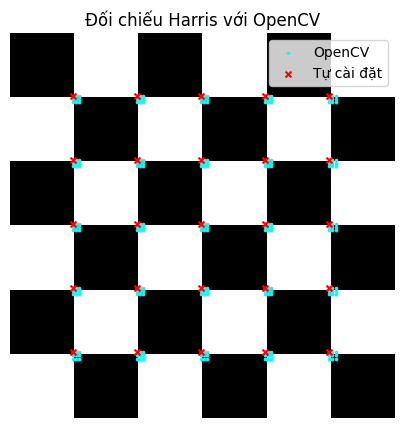

In [8]:
try:
    import cv2
    cv_R = cv2.cornerHarris(np.float32(img), blockSize=2, ksize=3, k=0.04)
    cv_mask = cv_R > 0.01 * cv_R.max()
    cv_rows, cv_cols = np.where(cv_mask)
    print("OpenCV cornerHarris candidates:", len(cv_rows))
    print("Harris tự cài đặt:", len(points))
    plt.figure(figsize=(6,5)); plt.imshow(img, cmap="gray")
    plt.scatter(cv_cols, cv_rows, s=10, c="cyan", marker=".", label="OpenCV")
    plt.scatter(points[:,1], points[:,0], s=18, c="red", marker="x", label="Tự cài đặt")
    plt.legend(); plt.title("Đối chiếu Harris với OpenCV"); plt.axis("off"); plt.show()
except ImportError:
    print("Chưa cài opencv-python. Bỏ qua cell đối chiếu; thuật toán chính không cần OpenCV.")

## 7. Kết luận cần ghi nhớ

- Góc có biến thiên mạnh theo hai hướng nên `det(M)` lớn và response Harris thường dương lớn.
- Cạnh có một hướng biến thiên yếu; vùng phẳng có cả hai hướng yếu.
- `sigma_d` điều khiển mức làm trơn trước gradient; `sigma_i` điều khiển vùng tích phân các tích gradient.
- NMS loại ứng viên lân cận không cực đại; `thresh_rel` kiểm soát độ mạnh tối thiểu.
- Harris cổ điển dùng một cặp tỉ lệ cố định nên không tự ước lượng kích thước đặc trưng.